Step 1: Import required libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout
from tensorflow.keras.optimizers import SGD

Step 2: Load and explore the dataset

In [1]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/

cp: cannot stat 'kaggle.json': No such file or directory


In [3]:
!kaggle datasets download -d salader/dogsvscats

Dataset URL: https://www.kaggle.com/datasets/salader/dogsvscats
License(s): unknown
100% 1.06G/1.06G [00:12<00:00, 89.0MB/s]



In [4]:
import zipfile
zip_ref = zipfile.ZipFile("/content/dogsvscats.zip")
zip_ref.extractall("/content")
zip_ref.close()

In [5]:
train_dir = "/content/catsvsdogs/train"

In [6]:
test_dir = "/content/catsvsdogs/test"

Step 3: Preprocess the images

In [7]:
IMG_SIZE = (150, 150)

Step 4: Apply data augmentation

In [8]:
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

In [9]:
validation_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

Step 5: Load images using flow_from_directory()

In [10]:
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(150, 150),
    batch_size=32,
    class_mode='categorical'
)

Found 20000 images belonging to 2 classes.


In [11]:
validation_generator = validation_datagen.flow_from_directory(
    test_dir,
    target_size=(150, 150),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 5000 images belonging to 2 classes.


In [12]:
print(train_generator.class_indices)

{'cats': 0, 'dogs': 1}


Step 6: Load the pre-trained VGG16 model

In [13]:
vgg16_base = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(150, 150, 3)
)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Step 7: Freeze the VGG16 layers

In [14]:
vgg16_base.trainable = False

Step 8: Build the custom classification model

In [15]:
model = Sequential([
    vgg16_base,
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(2, activation='softmax')
])

Step 9: Compile the model

In [16]:
model.compile(
    optimizer=SGD(learning_rate=0.001, momentum=0.9),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [17]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,812,610 (64.14 MB)

 Trainable params: 2,097,922 (8.00 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

Step 10: Train and evaluate the model

In [18]:
history = model.fit(
    train_generator,
    epochs=10,
    validation_data=validation_generator
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 198s 295ms/step - accuracy: 0.9000 - loss: 1.0201 - val_accuracy: 0.9604 - val_loss: 0.1249
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 178s 285ms/step - accuracy: 0.9238 - loss: 0.1983 - val_accuracy: 0.9530 - val_loss: 0.1195
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 180s 288ms/step - accuracy: 0.9257 - loss: 0.1943 - val_accuracy: 0.9622 - val_loss: 0.1083
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 182s 292ms/step - accuracy: 0.9304 - loss: 0.1712 - val_accuracy: 0.9612 - val_loss: 0.1102
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 181s 290ms/step - accuracy: 0.9344 - loss: 0.1600 - val_accuracy: 0.9640 - val_loss: 0.1175
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 177s 283ms/step - accuracy: 0.9373 - loss: 0.1557 - val_accuracy: 0.9658 - val_loss: 0.1089
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 175s 280ms/step - accuracy: 0.9370 - loss: 0.1640 - val_accuracy: 0.9646 - val_loss: 0.1041
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 176s 281ms/step - accuracy: 0.9405 -

Evaluate it:

In [19]:
loss, accuracy = model.evaluate(validation_generator)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100)

157/157 ━━━━━━━━━━━━━━━━━━━━ 13s 83ms/step - accuracy: 0.9646 - loss: 0.1016
Validation Loss: 0.10162914544343948
Validation Accuracy: 0.9646000266075134
Accuracy Percentage: 96.46000266075134


Visualize accuracy:

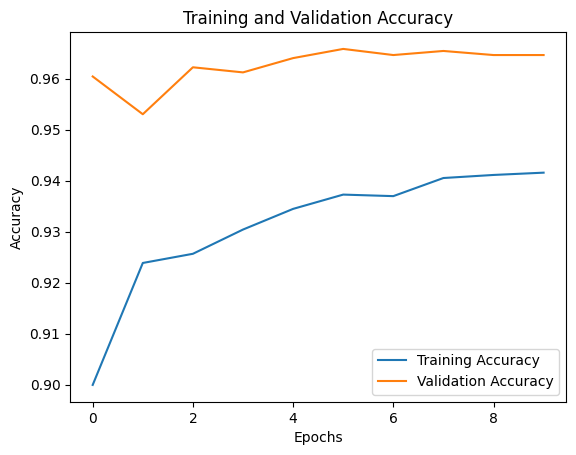

In [20]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

Visualize loss:

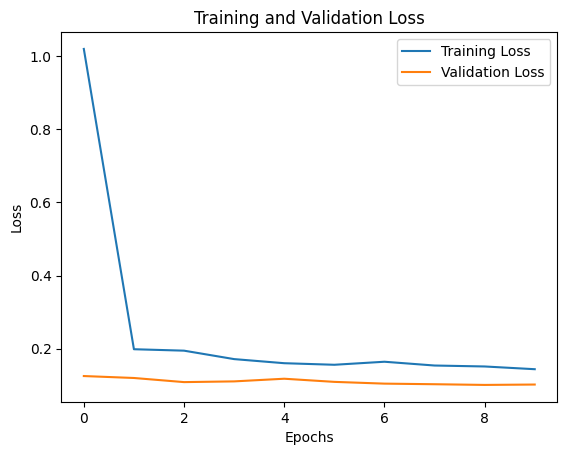

In [21]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

Step 11: Predict new images

In [22]:
from tensorflow.keras.preprocessing import image

def predict_image(img_path):

    img = image.load_img(
        img_path,
        target_size=(150, 150)
    )

    img_array = image.img_to_array(img)

    img_array = np.expand_dims(img_array, axis=0)

    img_array = preprocess_input(img_array)

    prediction = model.predict(img_array)

    predicted_class = np.argmax(prediction)

    class_labels = {
        0: 'Cat',
        1: 'Dog'
    }

    predicted_label = class_labels[predicted_class]

    confidence = prediction[0][predicted_class] * 100

    print("Predicted Class:", predicted_label)
    print("Confidence:", round(confidence, 2), "%")

    plt.imshow(img)
    plt.axis('off')
    plt.title(predicted_label)
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
Predicted Class: Cat
Confidence: 100.0 %


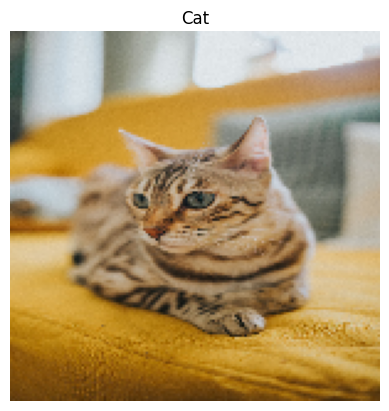

In [23]:
predict_image('/content/test_cat.jpg')